# 08 - Choosing a model with cross-validation

Stage 2 showed that the primary test set (43 cells) is too small to tell models apart: its RMSE could be anywhere from about 92 to 191 cycles. So the choice happens here, on the 41 training cells only, with cross-validation. The test sets aren't touched in this notebook.

Four models, all predicting log10(cycle life):

| Model | Inputs |
|---|---|
| A: mean | nothing, predicts the average training life |
| B: log_var line | log10(var(ΔQ)), straight line (the paper's model from notebook 06) |
| C: log_var curve | log10(var(ΔQ)) and its square, so the line can bend (the idea from notebook 06) |
| D: Elastic Net | all six features from notebook 07, scaled first |

Elastic Net is a linear model that shrinks weak features toward zero, or all the way to zero. How strongly it shrinks is picked by a second, inner cross-validation inside each training fold, so the outer folds never see that choice being made. The recipe is `elastic_net()` in `src/models.py`, so the later notebooks use exactly the same one.

**Cross-validation:** split the 41 cells into 5 folds, train on 4, measure on the 5th, and repeat with 20 different random splits (100 fits per model). There's one row per cell, so every split is automatically a split by cell: no cell is ever in both the training and the validation part.

In [1]:
import sys
sys.path.append("..")

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

from src.models import elastic_net

warnings.filterwarnings("ignore", category=UserWarning)

data = pd.read_csv("../data/features_stage3.csv", index_col="cell_id")
train = data[data["split"] == "train"]
assert train.index.is_unique  # one row per cell, so splitting rows = splitting cells

ALL = ["log_var", "q2", "q_max_minus_q2", "ir_change", "charge_time_first5", "t_avg_mean"]
y = np.log10(train["cycle_life"].values)
life = train["cycle_life"].values
print(len(train), "training cells")

41 training cells


In [2]:
MODELS = {
    "A: mean": (["log_var"], lambda: DummyRegressor()),
    "B: log_var line": (["log_var"], lambda: LinearRegression()),
    "C: log_var curve": (["log_var"], lambda: make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression())),
    "D: Elastic Net": (ALL, elastic_net),
}

cv = RepeatedKFold(n_splits=5, n_repeats=20, random_state=0)


def cross_validate(cols, make_model):
    X = train[cols].values
    rmse, mape = [], []
    for fit_idx, val_idx in cv.split(X):
        model = make_model().fit(X[fit_idx], y[fit_idx])
        pred = 10 ** model.predict(X[val_idx])
        true = life[val_idx]
        rmse.append(np.sqrt(np.mean((pred - true) ** 2)))
        mape.append(np.mean(np.abs(pred - true) / true) * 100)
    return np.array(rmse), np.array(mape)


fold_rmse, rows = {}, []
for name, (cols, make_model) in MODELS.items():
    rmse, mape = cross_validate(cols, make_model)
    fold_rmse[name] = rmse
    rows.append({"model": name, "CV RMSE (cycles)": rmse.mean(), "spread (sd)": rmse.std(), "CV MAPE (%)": mape.mean()})

results = pd.DataFrame(rows).set_index("model")
results["beats B in % of folds"] = [np.mean(fold_rmse[m] < fold_rmse["B: log_var line"]) * 100 for m in results.index]
results.round(1)

,CV RMSE (cycles),spread (sd),CV MAPE (%),beats B in % of folds
model,,,,
A: mean,296.8,155.3,30.8,0.0
B: log_var line,108.0,18.9,14.8,0.0
C: log_var curve,170.1,137.5,16.0,45.0
D: Elastic Net,81.6,16.7,11.0,89.0


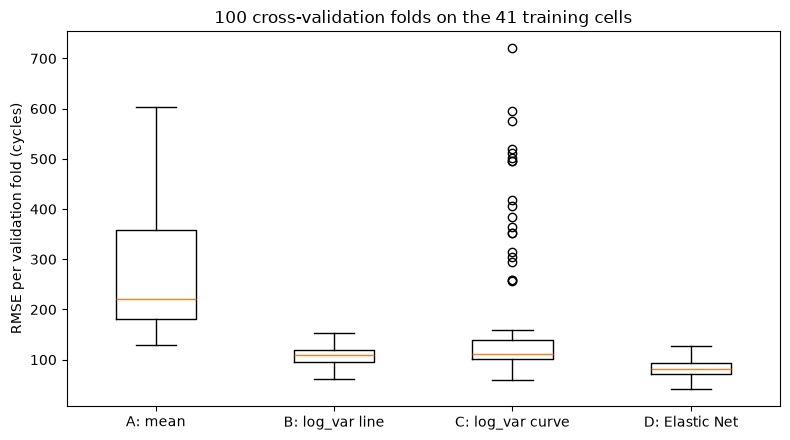

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(list(fold_rmse.values()), tick_labels=list(fold_rmse.keys()))
ax.set_ylabel("RMSE per validation fold (cycles)")
ax.set_title("100 cross-validation folds on the 41 training cells")
plt.tight_layout()
plt.savefig("../reports/figures/cv_rmse_models.png", dpi=120)
plt.show()

Model C has a much wider spread than B. What goes wrong in its bad folds? Look at the cell with the most extreme log_var, b1c1 (life 2,160), in the folds where it is held out.

In [4]:
X = train[["log_var"]].values
pos = list(train.index).index("b1c1")
held_out = {"B: log_var line": [], "C: log_var curve": []}
for fit_idx, val_idx in cv.split(X):
    if pos in val_idx:
        for name in held_out:
            model = MODELS[name][1]().fit(X[fit_idx], y[fit_idx])
            held_out[name].append(10 ** model.predict(X[[pos]])[0])
for name, preds in held_out.items():
    print(f"{name}: b1c1 predicted {np.mean(preds):.0f} cycles on average over {len(preds)} folds (true 2,160)")

B: log_var line: b1c1 predicted 2137 cycles on average over 20 folds (true 2,160)
C: log_var curve: b1c1 predicted 3307 cycles on average over 20 folds (true 2,160)


## What the Elastic Net keeps

Fitted once on all 41 training cells. The features are scaled, so the coefficients can be compared with each other. A coefficient of 0 means the model dropped that feature.

In [5]:
final = elastic_net().fit(train[ALL], y)
net = final[-1]
print(f"chosen shrinkage: alpha = {net.alpha_:.4f}, l1_ratio = {net.l1_ratio_}")
pd.Series(net.coef_, index=ALL, name="coefficient").round(4)

chosen shrinkage: alpha = 0.0479, l1_ratio = 0.1


log_var              -0.1152
q2                    0.0278
q_max_minus_q2       -0.0195
ir_change             0.0000
charge_time_first5    0.0341
t_avg_mean           -0.0000
Name: coefficient, dtype: float64

Which features carry the gain? Leave one out at a time and run the same cross-validation. This is only to understand the model. It doesn't change which model gets picked, because picking features this way on 41 cells would just fit the noise.

In [6]:
drop_one = {"all six": fold_rmse["D: Elastic Net"].mean()}
for feature in ALL[1:]:
    cols = [f for f in ALL if f != feature]
    drop_one[f"without {feature}"] = cross_validate(cols, elastic_net)[0].mean()
pd.Series(drop_one, name="CV RMSE (cycles)").round(1)

all six                       81.6
without q2                    87.9
without q_max_minus_q2        90.5
without ir_change             78.6
without charge_time_first5    89.0
without t_avg_mean            81.5
Name: CV RMSE (cycles), dtype: float64

In [7]:
results.round(2).to_csv("../reports/cv_results_stage3.csv")

## Notes

- The Elastic Net (D) is the best model: a CV RMSE of 81.6 cycles (11.0%) against 108.0 cycles (14.8%) for the paper's straight line (B). It is better in 89 of the 100 folds, and its spread is about the same (16.7 against 18.9), so the gain doesn't come from a few lucky folds.
- The curved model (C) is much worse: 170.1 cycles with a huge spread. When b1c1, the longest-lived training cell, is held out, the curve predicts 3,307 cycles on average for it (true 2,160), while the straight line predicts 2,137. With only one cell out at that end, a squared term just runs away. So the idea from notebook 06 doesn't work in this form, and C is out.
- What the Elastic Net uses: log_var by far the most (-0.115), then charge time (0.034), capacity at cycle 2 (0.028) and the early capacity rise (-0.020). It sets resistance change and mean temperature to exactly 0. With l1_ratio 0.1 it mostly shrinks features instead of dropping them.
- Capacity at cycle 2 and the capacity rise looked weak on their own in notebook 07 (r 0.33 and 0.15), but they help next to log_var. Leaving out the capacity rise, charge time or capacity at cycle 2 costs 6 to 9 cycles each.
- Leaving out resistance change gives 78.6 cycles, a little better than 81.6, and leaving out temperature changes nothing. I'm not acting on that. With 41 cells a 3-cycle difference is noise, and picking features from these numbers would tune the model to these exact cells. The Elastic Net already ignores both, so model D stays as planned, with all six inputs.
- I skipped LightGBM, which the plan marked as optional. A tree model has very little to learn from 41 cells.
- Next, step 3.4: fit D on all 41 training cells and measure it once on the primary test set.